<a href="https://colab.research.google.com/github/danielbatmanj/DATA-201/blob/main/DATA_201_project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project 1**
Heart Disease Prediction <br>
by Daniel Johnson

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, f1_score


In [ ]:
data = pd.read_csv("/content/drive/MyDrive/DATA_201/Projects/Project_1/Datasets/heart.csv")

# **Part 1**

1. Each row in the dataset represents a patient and about a dozen measurements of their vitals, their sex and ultimately if they had heart disease or not
2. The 3 predictors I believe will have the most impact are cholestorol, resting blood pressure and age.
3. The response vcariable, target, has 526 positives and 499 negatives, this seems relatively balanced to me


In [ ]:
data["target"].value_counts()

,proportion
target,
1,51.317073
0,48.682927


4. A false positive means the model says someone has heart disease when they actually don't. Meanwhile, a false negative is when the model says a patient doesn't have heart disease when they actually do.
5. I believe a false negative is much worse in this situation, since that would mean someone has an ailment but the model says they don't.

# **Part 2**

In [ ]:
data.shape

(1025, 14)

In [ ]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [ ]:
data[["age", "trestbps", "chol"]].describe()

,age,trestbps,chol
count,1025.000000,1025.000000,1025.00000
mean,54.434146,131.611707,246.00000
std,9.072290,17.516718,51.59251
min,29.000000,94.000000,126.00000
25%,48.000000,120.000000,211.00000
50%,56.000000,130.000000,240.00000
75%,61.000000,140.000000,275.00000
max,77.000000,200.000000,564.00000


2. Data contains no missing values
3. I don't believe any encoding needs to be done.

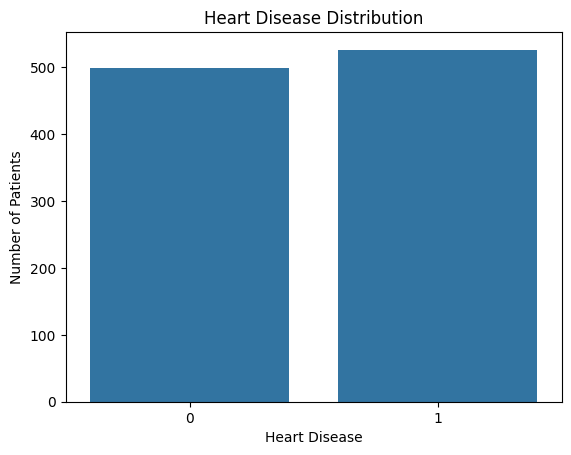

In [ ]:
sns.countplot(x="target", data=data)
plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease")
plt.ylabel ("Number of Patients")

plt.show()


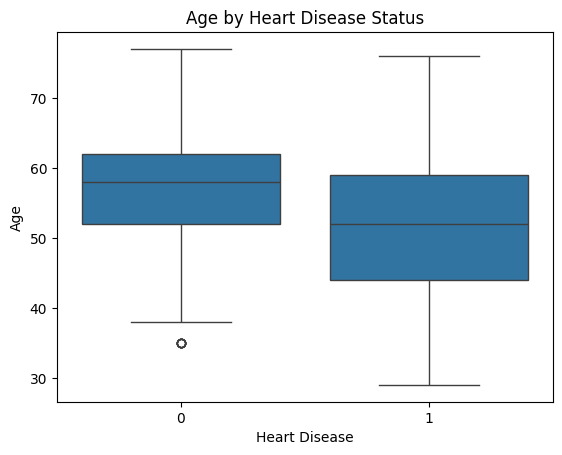

In [ ]:
sns.boxplot(x="target", y="age", data=data)

plt.title("Age by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Age")
plt.show()


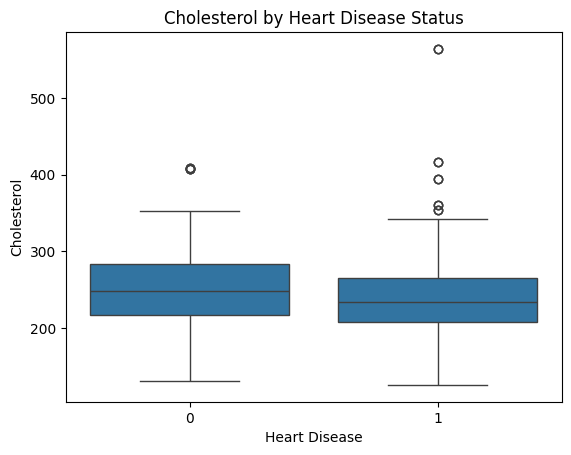

In [ ]:
sns.boxplot(x="target", y="chol", data=data)

plt.title("Cholesterol by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Cholesterol")
plt.show()


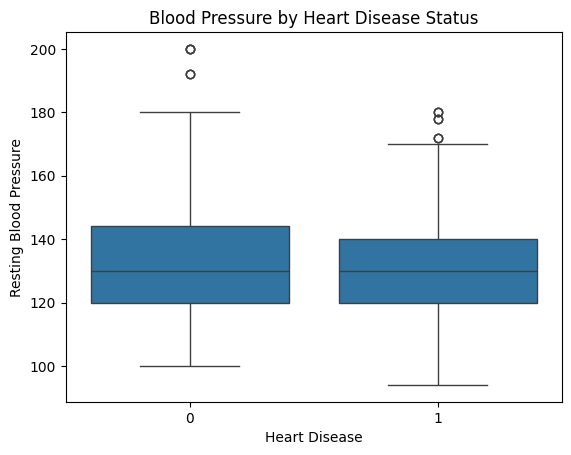

In [ ]:
sns.boxplot(x="target", y="trestbps", data=data)

plt.title("Blood Pressure by Heart Disease Status")
plt.xlabel("Heart Disease")
plt.ylabel("Resting Blood Pressure")
plt.show()


In [ ]:
x = data[["age", "trestbps", "chol"]]

y = data["target"]


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [ ]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

# **Part 3**

In [ ]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train_scaled, y_train)
logistic_pred = logistic_model.predict(x_test_scaled)
logistic_prob = logistic_model.predict_proba(x_test_scaled)[:, 1]

print("Logistic Regression Predictions:")
print(logistic_pred)

print("\nLogistic Regression Probabilities:")
print(logistic_prob)


Logistic Regression Predictions:
[0 1 0 0 0 0 1 1 1 1 0 0 1 1 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0
 0 1 0 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1 0 1 1
 0 1 1 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 1 0 1 1 0
 1 1 1 0 1 0 1 1 0 0 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 0
 1 1 1 1 0 1 1 0 0 0 0 1 1 1 1 0 1 1 0 1]

Logistic Regression Probabilities:
[0.43746694 0.57288992 0.47830089 0.4937866  0.47101598 0.46460086
 0.68645047 0.50064798 0.60599342 0.57288992 0.35956541 0.35070726
 0.50064798 0.65102603 0.26830355 0.35332613 0.70626097 0.48910697
 0.44063394 0.65282588 0.56455527 0.45142631 0.25150008 0.52096958
 0.45224385 0.48579544 0.42254182 0.65102603 0.28532697 0.46620453
 0.38769893 0.34437553 0.37394196 0.46941906 0.4106554  0.77774421
 0.48348577 0.39198811 0.57172247 0.30554167 0.37564511 0.60934538
 0.43441828 0.30554167 0.7173506  0.45056439 

In [ ]:
print("\nLogistic Regression Probabilities:")
print(logistic_prob)



Logistic Regression Probabilities:
[0.43746694 0.57288992 0.47830089 0.4937866  0.47101598 0.46460086
 0.68645047 0.50064798 0.60599342 0.57288992 0.35956541 0.35070726
 0.50064798 0.65102603 0.26830355 0.35332613 0.70626097 0.48910697
 0.44063394 0.65282588 0.56455527 0.45142631 0.25150008 0.52096958
 0.45224385 0.48579544 0.42254182 0.65102603 0.28532697 0.46620453
 0.38769893 0.34437553 0.37394196 0.46941906 0.4106554  0.77774421
 0.48348577 0.39198811 0.57172247 0.30554167 0.37564511 0.60934538
 0.43441828 0.30554167 0.7173506  0.45056439 0.68645047 0.52096958
 0.42435716 0.42727193 0.48749647 0.45142631 0.65282588 0.43788021
 0.58025471 0.5364425  0.70602438 0.69225997 0.6710042  0.5106523
 0.53041603 0.71220866 0.74677261 0.64465558 0.72169949 0.41065546
 0.55689862 0.74030266 0.50845408 0.54206849 0.61704922 0.48658298
 0.68102684 0.65437325 0.50359281 0.58105496 0.46540066 0.5874815
 0.64465558 0.77774421 0.71807722 0.74470262 0.72169949 0.50182481
 0.60572153 0.6715148  0.698

In [ ]:
lda_model = LinearDiscriminantAnalysis()

lda_model.fit(x_train_scaled, y_train)

lda_pred = lda_model.predict(x_test_scaled)
lda_prob = lda_model.predict_proba(x_test_scaled)[:, 1]

print("LDA Predictions:")
print(lda_pred)


LDA Predictions:
[0 1 0 0 0 0 1 0 1 1 0 0 0 1 0 0 1 0 0 1 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0
 0 1 0 0 1 0 0 1 0 1 1 0 0 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 1 1 1 1 1 0 1 1
 0 1 1 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 0 0 1 1 0 0 0 1 1 1 1 0 1 1 1 0 1 1 0
 1 1 1 0 1 0 1 1 0 0 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 0
 1 1 1 1 0 1 1 0 0 0 0 1 1 1 1 0 1 1 0 1]


In [ ]:
qda_model = QuadraticDiscriminantAnalysis()

qda_model.fit(x_train_scaled, y_train)

qda_pred = qda_model.predict(x_test_scaled)
qda_prob = qda_model.predict_proba(x_test_scaled)[:, 1]

print("QDA Predictions:")
print(qda_pred)


QDA Predictions:
[0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 1 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0
 0 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 0 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 0 1 1
 0 1 1 1 0 0 1 1 1 1 0 0 1 1 1 1 0 0 0 0 1 1 0 0 0 1 0 0 1 0 1 1 1 0 1 1 0
 1 1 1 0 1 0 1 1 0 0 1 1 0 1 1 0 1 0 0 1 0 0 0 1 1 1 1 0 1 1 0 0 0 1 1 0 0
 1 1 1 0 0 1 1 0 0 0 0 1 1 1 0 0 1 1 0 0]


In [ ]:
k_values = range(1, 21)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        x_train_scaled,
        y_train,
        cv = 10,
        scoring="accuracy"
    )

    cv_scores.append(scores.mean())


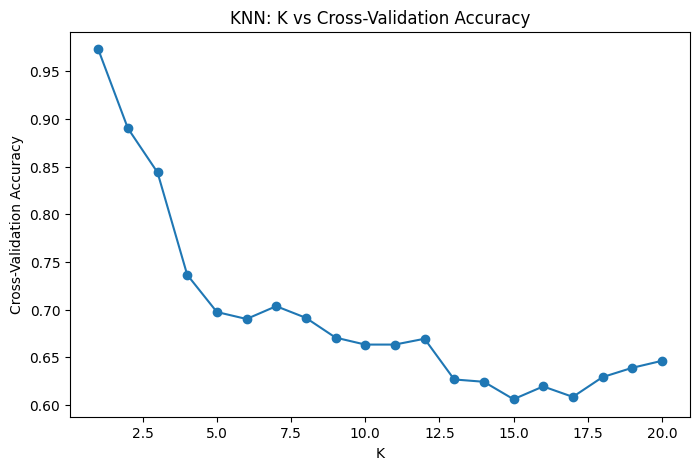

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, cv_scores, marker="o")

plt.xlabel("K")
plt.ylabel("Cross-Validation Accuracy")
plt.title("KNN: K vs Cross-Validation Accuracy")

plt.show()

In [ ]:
best_k = k_values[np.argmax(cv_scores)]

print("Best K:", best_k)
print("Best CV Accuracy:", max(cv_scores))

Best K: 1
Best CV Accuracy: 0.9731707317073172


I selected a K of 1 since it's almost 100% accurate.

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)

knn_model.fit(x_train_scaled, y_train)

knn_pred = knn_model.predict(x_test_scaled)
knn_prob = knn_model.predict_proba(x_test_scaled)[:, 1]

print("KNN Predictions:")
print(knn_pred)


KNN Predictions:
[0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0 1 1 0 1 0 0 1 0 1 1 0 1 0 0 1
 0 0 1 0 1 1 1 0 0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 1 0 1 0 0 1 1 1 1 0 1 1
 0 0 1 0 0 0 1 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1
 0 1 1 1 0 1 1 1 1 1 0 0 1 1 0 0 0 0 0 0 0 1 0 0 1 0 1 0 1 1 1 0 0 0 0 1 1
 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 1 0 0 0 1 1 1 1 0 1 0 1 1 0 1 1 0
 1 0 0 0 1 0 1 1 0 1 0 1 1 0 1 0 0 0 1 1]


# **Part 4**
1. I chose LDA, which is below a normal threshold of 90%, but I'm suspicious of the 100% accuracy of KNN as I believe I did something wrong.

In [ ]:
logistic_cm = confusion_matrix(y_test, logistic_pred)

print("Logistic Regression Confusion Matrix:")
print(logistic_cm)

Logistic Regression Confusion Matrix:
[[49 51]
 [32 73]]


In [ ]:
lda_cm = confusion_matrix(y_test, lda_pred)

print("LDA Confusion Matrix:")
print(lda_cm)

LDA Confusion Matrix:
[[51 49]
 [32 73]]


In [ ]:
qda_cm = confusion_matrix(y_test, qda_pred)

print("QDA Confusion Matrix:")
print(qda_cm)

QDA Confusion Matrix:
[[57 43]
 [45 60]]


In [ ]:
knn_cm = confusion_matrix(y_test, knn_pred)

print("KNN Confusion Matrix:")
print(knn_cm)

KNN Confusion Matrix:
[[100   0]
 [  0 105]]


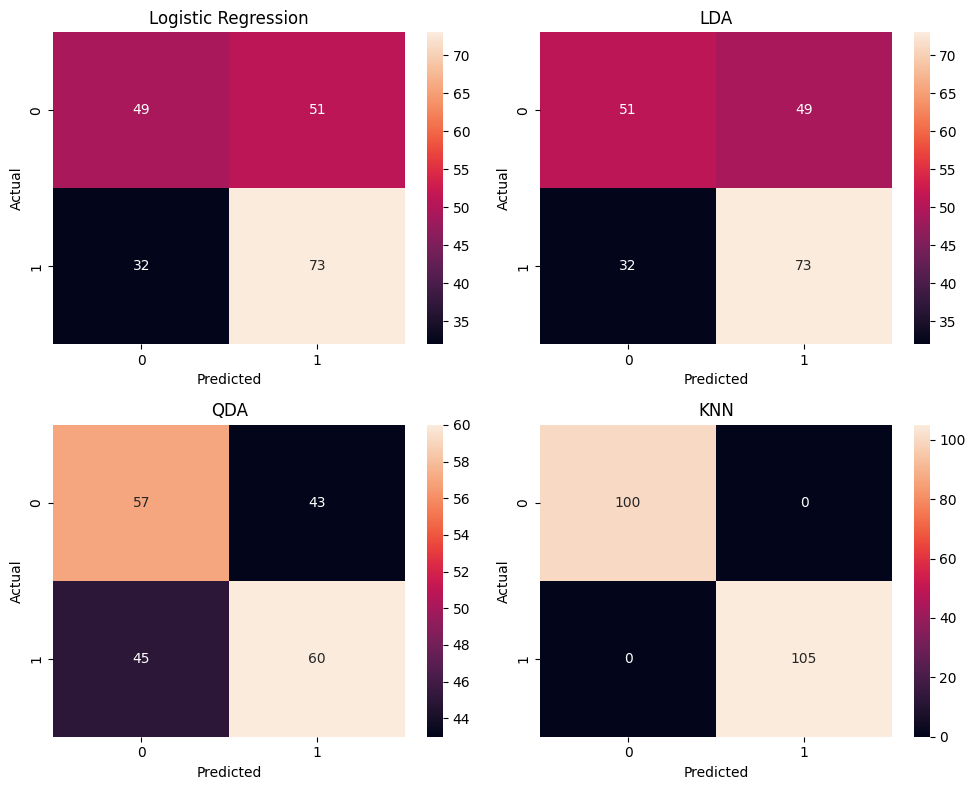

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

sns.heatmap(logistic_cm, annot=True, fmt="d", ax=axes[0, 0])
axes[0, 0].set_title("Logistic Regression")
axes[0, 0].set_xlabel("Predicted")
axes[0, 0].set_ylabel("Actual")

sns.heatmap(lda_cm, annot=True, fmt="d", ax=axes[0, 1])
axes[0, 1].set_title("LDA")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

sns.heatmap(qda_cm, annot=True, fmt="d", ax=axes[1, 0])
axes[1, 0].set_title("QDA")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Actual")

sns.heatmap(knn_cm, annot=True, fmt="d", ax=axes[1, 1])
axes[1, 1].set_title("KNN")
axes[1, 1].set_xlabel("Predicted")
axes[1, 1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
def get_metrics(y_true, y_pred, y_prob):
    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    specificity = tn / (tn + fp)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_prob)

    return [accuracy, precision, recall, specificity, f1, roc_auc]

In [ ]:
logistic_metrics = get_metrics(
    y_test,
    logistic_pred,
    logistic_prob
)

lda_metrics = get_metrics(
    y_test,
    lda_pred,
    lda_prob
)

qda_metrics = get_metrics(
    y_test,
    qda_pred,
    qda_prob
)

knn_metrics = get_metrics(
    y_test,
    knn_pred,
    knn_prob
)

In [ ]:
results = pd.DataFrame(
    [logistic_metrics, lda_metrics, qda_metrics, knn_metrics],
    columns=[
        "Accuracy",
        "Precision",
        "Recall",
        "Specificity",
        "F1",
        "ROC-AUC"
    ],
    index=[
        "Logistic Regression",
        "LDA",
        "QDA",
        "KNN"
    ]
)

results.round(3)

,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC
Logistic Regression,0.595,0.589,0.695,0.49,0.638,0.613
LDA,0.605,0.598,0.695,0.51,0.643,0.614
QDA,0.571,0.583,0.571,0.57,0.577,0.617
KNN,1.000,1.000,1.000,1.00,1.000,1.000


# **Part 5**
Based on what I've learned, LDA seems to be a little bit better then logistic regression, and I definitely did something wrong with regards to KNN because there is no way it should be 100% accurate.

# **Part 6**
The ROC-AUC below tells us that QDA, LDA and logistic are very close, but QDA is actually a tiny bit more accurate. It also shows again that KNN is somehow perfect, which I am still suspicious of.

In [ ]:
logistic_fpr, logistic_tpr, _ = roc_curve(y_test, logistic_prob)
lda_fpr, lda_tpr, _ = roc_curve(y_test, lda_prob)
qda_fpr, qda_tpr, _ = roc_curve(y_test, qda_prob)
knn_fpr, knn_tpr, _ = roc_curve(y_test, knn_prob)

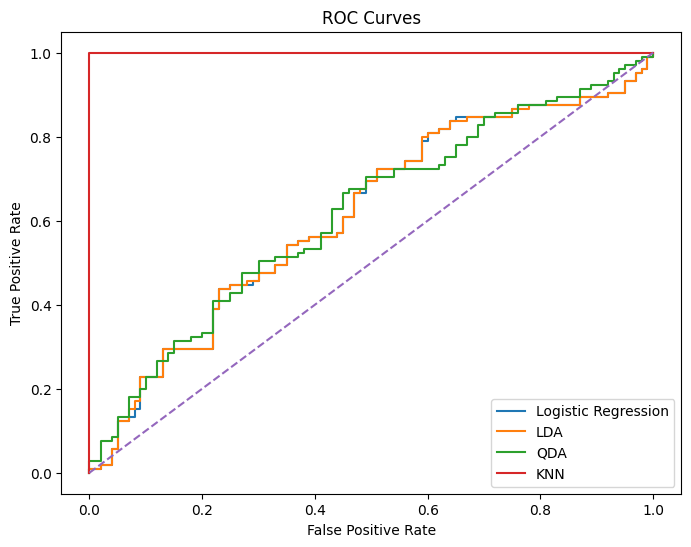

In [ ]:
plt.figure(figsize=(8, 6))

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label="Logistic Regression"
)

plt.plot(
    lda_fpr,
    lda_tpr,
    label="LDA"
)

plt.plot(
    qda_fpr,
    qda_tpr,
    label="QDA"
)

plt.plot(
    knn_fpr,
    knn_tpr,
    label="KNN"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()

plt.show()

In [ ]:
results["ROC-AUC"].sort_values(ascending=False).round(3)

,ROC-AUC
KNN,1.000
QDA,0.617
LDA,0.614
Logistic Regression,0.613


# **Part 7**
1. The ROC-AUC shows that QDA, LDA and logistic are very similar, but the confusion matrix shows that while QDA has more true negatives, it has less true positives and more false negatives.
2. In this situation I prefer to have less false negatives to ensure that we are missing as few patients as possible. LDA and logistic are within a couple of percentage points, but with this data LDA is slightly beter, so that's what I chose.
3. One big limitation in this analysis I see is using the same model on data that has both male and female patients. If this were a situation, I would build 2 seperate models, one for males and one for females since the conditions that give each heart disease are different.

At the endc I decided to ask AI why KNN was perfect, and it turns out that a majority of the data points in the dataset are duplicates. I'm sure this affected the other 3 models as well, so I would re-do the analysis with the duplicates removed.

In [ ]:
print("Number of duplicate rows:", data.duplicated().sum())

Number of duplicate rows: 723
